# 📘 03_driver_feedback_poc.ipynb

This notebook demonstrates how to use SHAP to interpret a trained XGBoost model for tire degradation prediction.

In [2]:
# --- Load packages ---
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from assign_turns_to_df import assign_turns_to_dataframe
from degradation_components_full import (
    compute_friction_penalty,
    compute_thermal_aging_penalty,
    compute_asymmetric_penalty,
    compute_transient_penalty,
    compute_corner_g_loss_by_turn,
    compute_combined_degradation,
    estimate_per_tire_fx,
    estimate_slip_power
)

# --- Load model and data ---
model = joblib.load("best_xgb_model.joblib")


In [ ]:
#load and setup unseen stint

# 1. Load your data
df = pd.read_csv("parquet_files\\finaltest_12hz_1stint.csv")

# drop warmup lap and stop at lap 15
laps_to_plot = np.arange(1,16)

df = df[(df["Lap"].isin(laps_to_plot))]

df["LatG"] = df["LatAccel"].abs()
df["LongG"] = df["LongAccel"].abs()

df['source_file'].unique()

# --- 2. Engineer Rate-of-Change Features ---
# ~250ms smoothing at 12Hz
def compute_input_roc(df, cols, sampling_rate_hz=12):
    for col in cols:
        smoothed = df[col].rolling(3, min_periods=1).mean()
        df[f"{col}_rate"] = smoothed.diff() * sampling_rate_hz
    return df


# lag features
hz = 12
window = 3 * hz  # 3 seconds
step = hz // 4

# base features gathered from EDA???
base_features = [
    "Throttle", "Brake", "SteeringWheelAngle",
    "LatAccel", "LongAccel", "Speed",
    "LFtempM", "RFtempM", "LRtempM", "RRtempM",
    "LFshockDefl", "RFshockDefl", "LRshockDefl", "RRshockDefl",
    "LFpressure", "RFpressure", "LRpressure", "RRpressure",
    "LatG", "VertAccel", "PitchRate"
    , "LFspeed", "RFspeed", "LRspeed", "RRspeed"
]

# Initialize empty list to collect updated chunks
updated_chunks = []

for stint_id, stint_df in df.groupby("source_file", sort=False):
    #print(stint_id)
    stint_df = stint_df.copy()

    stint_df = assign_turns_to_dataframe(stint_df, "turn_ranges_laguna_seca.csv")
    stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN
    stint_df["corner_g_loss"] = compute_corner_g_loss_by_turn(stint_df)
    stint_df = estimate_per_tire_fx(stint_df)
    stint_df["slip_power"] = estimate_slip_power(stint_df)

    # Generate lagged features efficiently
    lagged_cols = []
    for feature in base_features:
        for lag in range(0, window + 1, step):
            col_name = f"{feature}_lag_{lag}"
            lagged_cols.append(stint_df[feature].shift(lag).rename(col_name))

    # Concatenate all lagged columns at once
    lagged_df = pd.concat(lagged_cols, axis=1)

    # Combine with original df (use .copy() to defragment memory)
    stint_df = pd.concat([stint_df.copy(), lagged_df], axis=1)


    input_signals = ['Throttle', 'Brake', 'SteeringWheelAngle']  # Extend as needed
    stint_df = compute_input_roc(stint_df, input_signals)

    # Recompute each degradation component
    stint_df["friction_penalty"] = compute_friction_penalty(stint_df)
    stint_df["transient_penalty"] = compute_transient_penalty(stint_df)
    stint_df["asym_penalty"] = compute_asymmetric_penalty(stint_df)
    stint_df["vulcan_penalty"] = compute_thermal_aging_penalty(stint_df)
    stint_df = compute_combined_degradation(stint_df)

    # Clip the degradation deltas
    lower = stint_df['deg_delta_3s'].quantile(0.01)
    upper = stint_df['deg_delta_3s'].quantile(0.99)
    stint_df['deg_delta_3s'] = stint_df['deg_delta_3s'].clip(lower, upper)

    stint_df = stint_df.dropna(subset=["deg_delta_3s"]).reset_index(drop=True) # drop NaN scores - should be at beginning and end

    updated_chunks.append(stint_df)

# Concatenate all updated stints back into a single DataFrame
df = pd.concat(updated_chunks, ignore_index=True)

#df["combined_degradation"] = df.groupby("stint_id")["combined_degradation"].transform(lambda x: x - x.min())
    
# Separate features and target
top_features = ['Yaw', 'Throttle_lag_36', 'LatG_lag_15', 'LRpressure_lag_24', 'LRpressure', 'Brake_rate', 'LongAccel_lag_36', 'Pitch', 'LRtempM_lag_21', 'Brake_lag_33', 'Speed_lag_36', 'LFpressure', 'Roll', 'Throttle_rate', 'Brake', 'Turn', 'Throttle_lag_24', 'LatG', 'RFspeed', 'SteeringWheelAngle', 'SteeringWheelAngle_rate', 'Throttle', 'RFpressure', 'SteeringWheelAngle_lag_6', 'RFspeed_lag_36', 'LongG', 'LFpressure_lag_9', 'Alt', 'LongAccel_lag_24', 'LRspeed', 'RRpressure_lag_3', 'Brake_lag_36', 'RFshockDefl_lag_0']
target_col = "deg_delta_3s"



y_test = df["deg_delta_3s"]
X_test = df[top_features]

#df_test = pd.read_csv("unseen_stint.csv")


C:\Users\cisan\AppData\Local\Temp\ipykernel_3836\605272453.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  stint_df["Turn"] = stint_df["Turn"].fillna(-1) # to eliminate NaN


In [4]:

#X_test = df_test.drop(columns=["degradation_delta_3s", "source_file"], errors='ignore')
#y_true = df_test["degradation_delta_3s"]

# --- Initialize SHAP explainer and values ---
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

## 🔍 Global Feature Importance (SHAP Summary Plot)

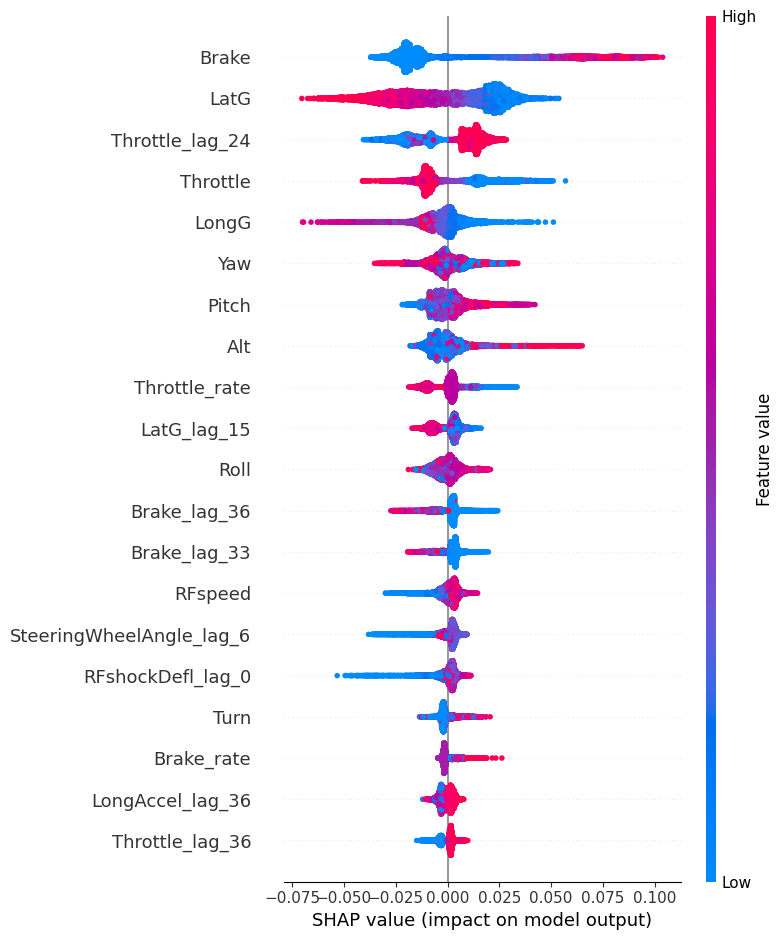

In [5]:
shap.summary_plot(shap_values, X_test)

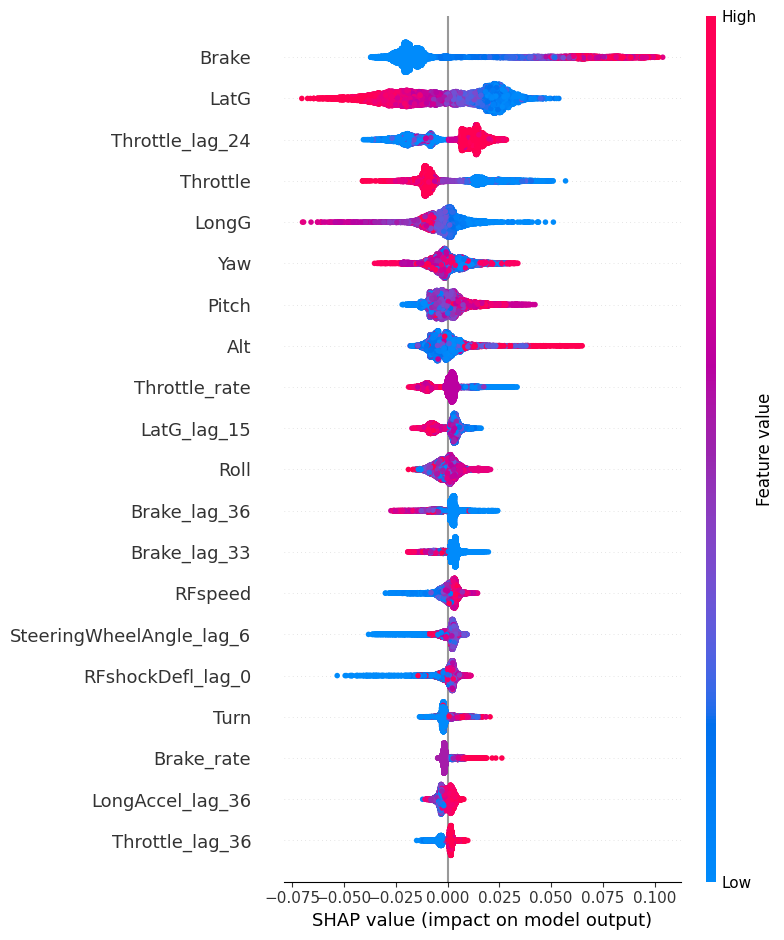

In [10]:
# Filter X_test and shap_values where Turn is not null
turning_mask = ~X_test['Turn'].isna()

# Subset the data
X_turning = X_test[turning_mask]
shap_turning = shap_values[turning_mask]

# Plot SHAP summary just for turning zones
shap.summary_plot(shap_turning, X_turning)

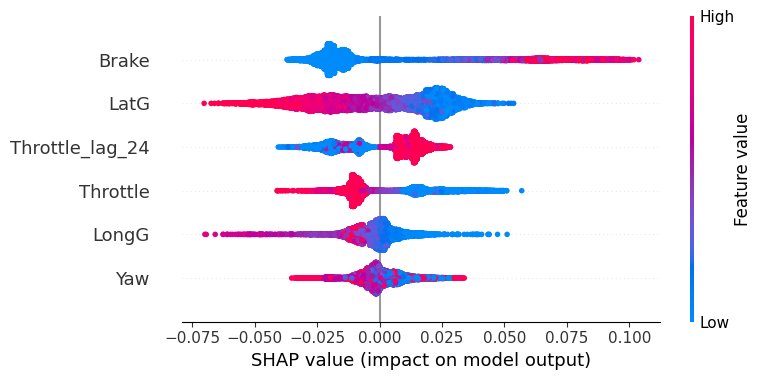

In [14]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Compute mean absolute SHAP values across all samples
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Get indices of top 5 features
top5_indices = np.argsort(mean_abs_shap)[-6:][::-1]

# Subset SHAP values and feature names
top5_shap_values = shap_values[:, top5_indices]
top5_feature_names = [top_features[i] for i in top5_indices]

# Plot top 5 features
shap.summary_plot(top5_shap_values, X_test.iloc[:, top5_indices], feature_names=top5_feature_names)

## 🎯 Local Explanation for a Specific Moment

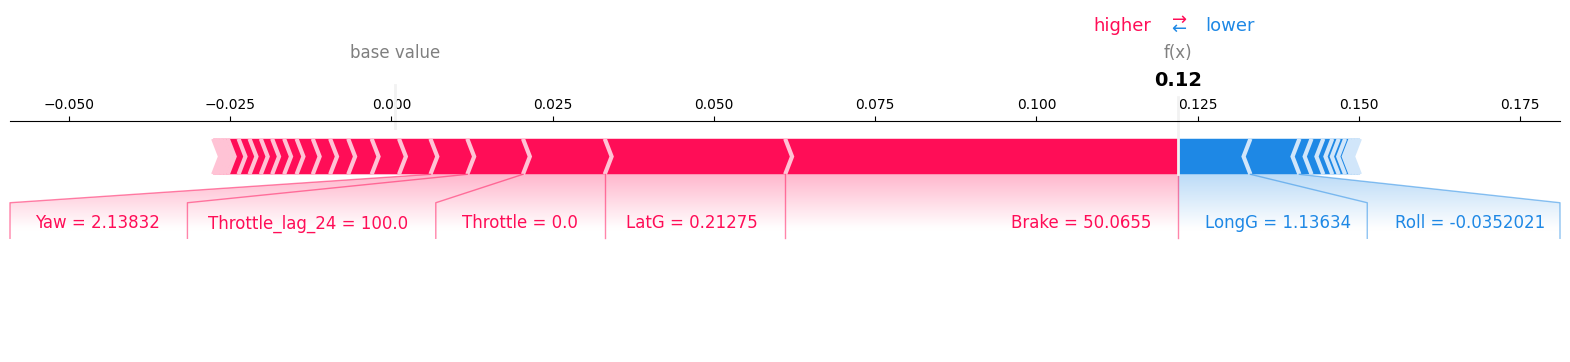

In [6]:
# Choose an index for a lap/turn with notable degradation
index = 500
shap.force_plot(explainer.expected_value, shap_values[index], X_test.iloc[index], matplotlib=True)

## 📈 SHAP Value Evolution Over Time

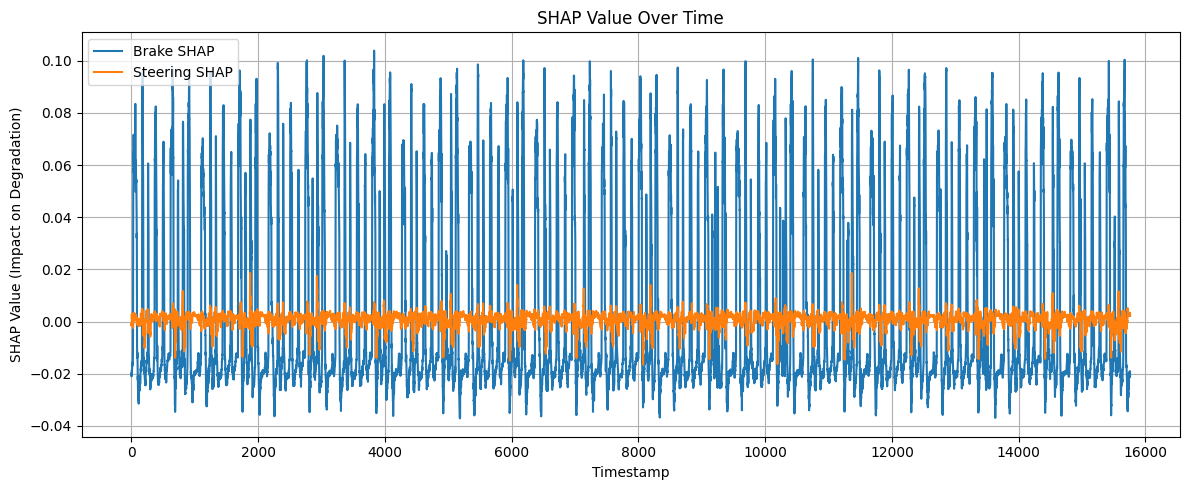

In [8]:
df_test = df[top_features + ["deg_delta_3s"]]

shap_df = pd.DataFrame(shap_values, columns=X_test.columns)
shap_df["timestamp"] = df_test.get("Timestamp", df_test.index)

plt.figure(figsize=(12, 5))
plt.plot(shap_df["timestamp"], shap_df["Brake"], label="Brake SHAP")
plt.plot(shap_df["timestamp"], shap_df["SteeringWheelAngle"], label="Steering SHAP")
plt.legend()
plt.title("SHAP Value Over Time")
plt.xlabel("Timestamp")
plt.ylabel("SHAP Value (Impact on Degradation)")
plt.grid(True)
plt.tight_layout()
plt.show()

## 🔥 SHAP for High-Degradation Moments Only

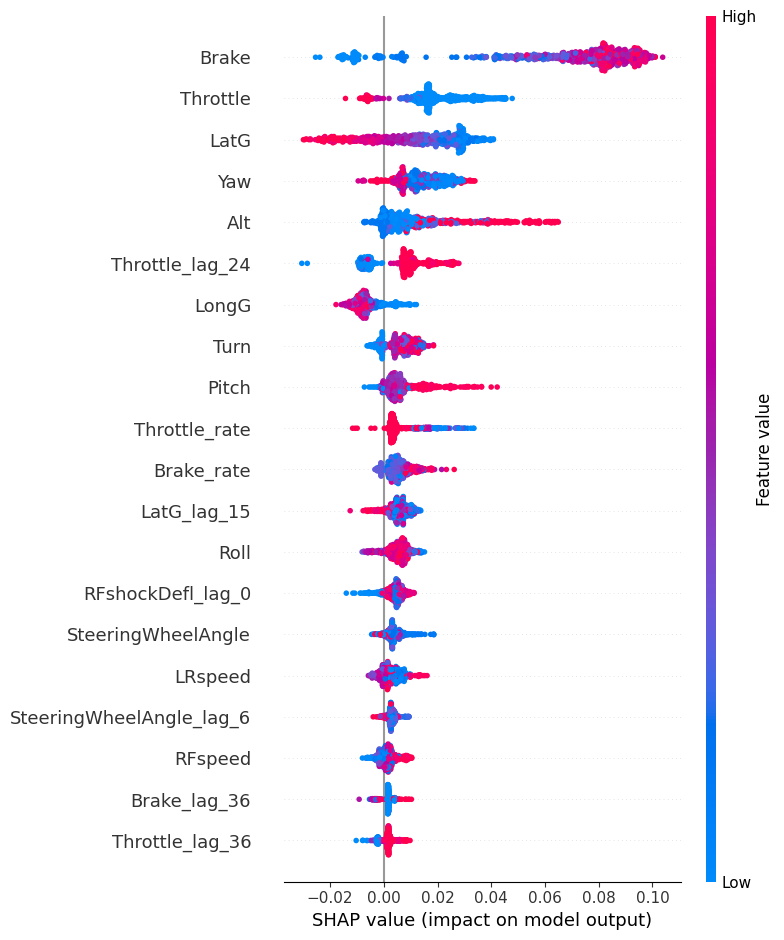

In [11]:
extreme_idx = y_test[y_test > 0.2].index
shap.summary_plot(shap_values[extreme_idx], X_test.iloc[extreme_idx])

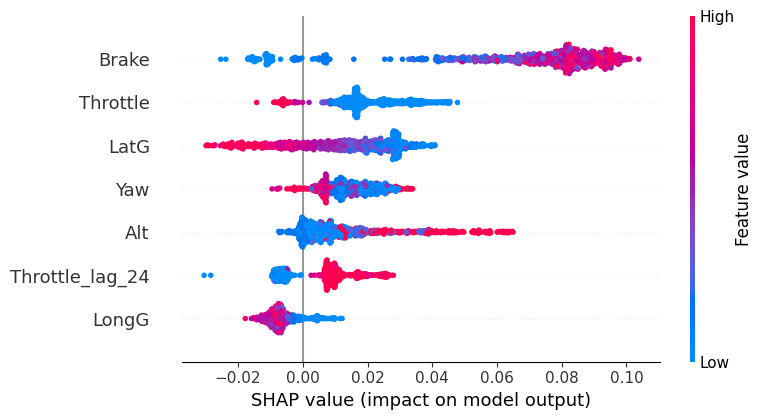

: 

In [ ]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# 1. Identify high degradation records
high_deg_mask = y_test > 0.20
X_high_deg = X_test[high_deg_mask]
shap_high_deg = shap_values[high_deg_mask]

# 2. Compute mean absolute SHAP per feature for just high-deg records
mean_abs_shap = np.abs(shap_high_deg).mean(axis=0)

# 3. Get indices of top 5 most important features
top5_indices = np.argsort(mean_abs_shap)[-7:][::-1]
top5_feature_names = [X_test.columns[i] for i in top5_indices]

# 4. Subset SHAP and feature data
top5_shap_values = shap_high_deg[:, top5_indices]
X_high_deg_top5 = X_high_deg.iloc[:, top5_indices]

# 5. Plot the summary plot
shap.summary_plot(top5_shap_values, X_high_deg_top5, feature_names=top5_feature_names)


In [ ]:
import shap
import matplotlib.pyplot as plt
import numpy as np

# Compute mean absolute SHAP values across all samples
mean_abs_shap = np.abs(shap_values).mean(axis=0)

# Get indices of top 5 features
top5_indices = np.argsort(mean_abs_shap)[-6:][::-1]

# Subset SHAP values and feature names
top5_shap_values = shap_values[:, top5_indices]
top5_feature_names = [top_features[i] for i in top5_indices]

# Plot top 5 features
shap.summary_plot(top5_shap_values, X_test.iloc[:, top5_indices], feature_names=top5_feature_names)